In [1]:
#Viết hàm fir_echo(x, fs, delay_ms, a) thực hiện bộ lọc FIR Echo theo phương trình sai phân (2).
import numpy as np
def fir_echo(x,fs,delay_ms,a):
    D = int(delay_ms * 1e-3 *fs)
    y = np.zeros(len(x) + D)
    y[:len(x)] = x
    y[D:D + len(x)] += a * x
    return y

In [4]:
#2. Áp dụng hiệu ứng lên file âm thanh chuẩn (guitar hoặc vocal):
from scipy.io.wavfile import read
from IPython.display import Audio, display
fs, x = read("guitar1.wav")
x = x.astype(np.float32)
if x.ndim == 2:
    x = np.mean(x, axis=1)
x = x / np.max(np.abs(x))

delays = [5, 20, 150, 350]

for delay in delays:
    y = fir_echo(x, fs, delay, 0.6)

    print(f"Delay = {delay} ms, a = {0.6}")
    display(Audio(y, rate=fs))

delays2 = 200 
a2 = [0.2, 0.5, 0.85]
for a in a2:
    y = fir_echo(x, fs, delays2, a )
    print(f"Delay = {delays2} ms, a = {a}")
    display(Audio(y, rate=fs))

Delay = 5 ms, a = 0.6


Delay = 20 ms, a = 0.6


Delay = 150 ms, a = 0.6


Delay = 350 ms, a = 0.6


Delay = 200 ms, a = 0.2


Delay = 200 ms, a = 0.5


Delay = 200 ms, a = 0.85


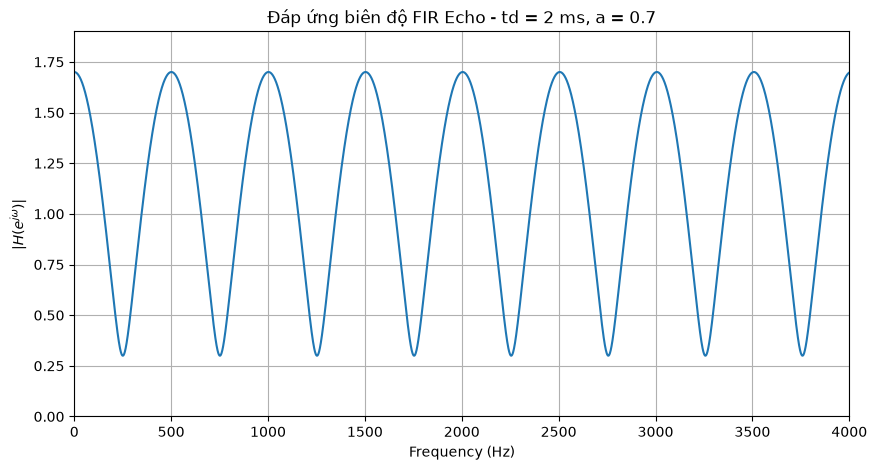

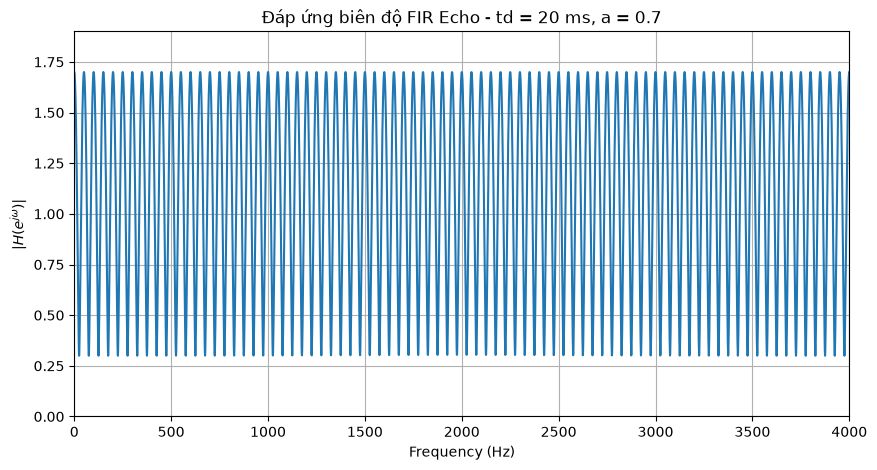

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs = 44100
a = 0.7

f = np.linspace(0, 4000, 4000)

td = 2
D = int(td * 1e-3 * fs)

H = np.sqrt(
    1 + a**2 +
    2*a*np.cos(2*np.pi*f*D/fs)
)

plt.figure(figsize=(10, 5))
plt.plot(f, H)

plt.title("Đáp ứng biên độ FIR Echo - td = 2 ms, a = 0.7")
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"$|H(e^{j\omega})|$")
plt.xlim(0, 4000)
plt.ylim(0, 1.9)
plt.grid(True)

plt.show()


td = 20
D = int(td * 1e-3 * fs)

H = np.sqrt(
    1 + a**2 +
    2*a*np.cos(2*np.pi*f*D/fs)
)

plt.figure(figsize=(10, 5))
plt.plot(f, H)

plt.title("Đáp ứng biên độ FIR Echo - td = 20 ms, a = 0.7")
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"$|H(e^{j\omega})|$")
plt.xlim(0, 4000)
plt.ylim(0, 1.9)
plt.grid(True)

plt.show()